In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import time


from utils_ML import score_dataset
from utils_preproces import ols_fit, y_distribution_plot, corr_heatmap_plot, make_mi_scores, preprocess_data

from sklearn.ensemble import RandomForestRegressor, VotingRegressor, ExtraTreesRegressor
from xgboost import XGBRegressor, plot_importance
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor


from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold


from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import QuantileTransformer

from sklearn.metrics import mean_absolute_error


from scikeras.wrappers import KerasRegressor
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
import tensorflow as tf
from tensorflow.keras import Input

import random
from heapq import nsmallest

2026-02-26 11:25:54.518946: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-02-26 11:25:54.530885: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1772105154.545214   40661 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1772105154.549668   40661 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1772105154.560500   40661 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

In [2]:
# Set Matplotlib defaults
plt.style.use("seaborn-v0_8-white")
plt.rc("figure", autolayout=True)
plt.rc(
    "axes",
    labelweight="bold",
    labelsize="large",
    titleweight="bold",
    titlesize=14,
    titlepad=10,
)

In [3]:
# Define pretty labels once
PRETTY_LABELS = {
    "U_lsr":        r"$U_{\mathrm{LSR}}\, [km/s]$",
    "V_lsr":        r"$V_{\mathrm{LSR}}\, [km/s]$",
    "W_lsr":        r"$W_{\mathrm{LSR}}\, [km/s]$",
    "UV_lsr":       r"$UV_{\mathrm{LSR}}\, [km/s]$",
    "UW_lsr":       r"$UW_{\mathrm{LSR}}\, [km/s]$",
    "VW_lsr":       r"$VW_{\mathrm{LSR}}\, [km/s]$ ",
    "UVW_lsr":      r"$UVW_{\mathrm{LSR}}\, [km/s]$",
    "abs_U_lsr":    r"$|U|_{\mathrm{LSR}}\, [km/s]$",
    "abs_W_lsr":    r"$|W|_{\mathrm{LSR}}\, [km/s]$",
    "P_gal":        r"$P_{\mathrm{gal}}\, [\%]$",
    "rapo":         r"$R_{\mathrm{apo}}\, [Kpc]$",
    "rperi":        r"$R_{\mathrm{peri}}\, [Kpc]$",
    "zmax":         r"$Z_{\max}\, [Kpc]$",
    "eccentricity": r"$e$",
    "R_mean":       r"$R_{\mathrm{mean}}\, [Kpc]$",
}

In [4]:
# Fix random state
random_state = 42

In [5]:
harps = pd.read_csv('harps_final_for_feh.csv')
apogee = pd.read_csv('apogee_final_for_feh.csv')
galah = pd.read_csv('galah_final_for_feh.csv')


print (f'harps contains {len(harps)} stars')
print (f'apogee contains {len(apogee)} stars')    
print (f'galah contains {len(galah)} stars')

harps contains 798 stars
apogee contains 45726 stars
galah contains 71591 stars


### Spliting data into Trianing and Testing sets

In [ ]:
# Split APOGEE
apogee_train_full, apogee_test = train_test_split(apogee, test_size=0.1, random_state=random_state)
X_apogee_train = apogee_train_full.drop(columns=['fe_h'])
y_apogee_train = apogee_train_full['fe_h']
X_apogee = apogee.drop(columns=['fe_h'])
y_apogee = apogee['fe_h']
X_apogee_test = apogee_test.drop(columns=['fe_h'])
y_apogee_test = apogee_test['fe_h']

# Split GALAH
galah_train_full, galah_test = train_test_split(galah, test_size=0.1, random_state=random_state)
X_galah_train = galah_train_full.drop(columns=['fe_h'])
y_galah_train = galah_train_full['fe_h']
X_galah = galah.drop(columns=['fe_h'])
y_galah = galah['fe_h']
X_galah_test = galah_test.drop(columns=['fe_h'])
y_galah_test = galah_test['fe_h']


# HARPS — no split
X_harps = harps.drop(columns=['fe_h'])
y_harps = harps['fe_h']

# Combine APOGEE and GALAH train sets
X_combined_train = pd.concat([X_apogee_train, X_galah_train], ignore_index=True)
y_combined_train = pd.concat([y_apogee_train, y_galah_train], ignore_index=True)

# Combine APOGEE and GALAH sets
X_combined = pd.concat([X_apogee, X_galah], ignore_index=True)
y_combined = pd.concat([y_apogee, y_galah], ignore_index=True)

full_df = pd.concat([apogee, harps], ignore_index=True)
X_full = full_df.drop(columns=['fe_h'])
y_full = full_df['fe_h']

In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold
import numpy as np
import time

def model_test_CV_models(X, y, models, k=5, random_state=42):
    """
    Perform k-fold cross-validation for multiple models.
    Returns mean and std of RMSE, MAE, and R2.
    """
    kf = KFold(n_splits=k, shuffle=True, random_state=random_state)
    results = {}

    for name, model in models.items():
        print(f"Scoring model: {name}")
        start_time = time.time()

        rmse_scores = []
        mae_scores = []
        r2_scores = []

        for train_index, test_index in kf.split(X, y):
            X_train, X_test = X.iloc[train_index], X.iloc[test_index]
            y_train, y_test = y.iloc[train_index], y.iloc[test_index]

            # Special handling for scikeras models
            if isinstance(model, KerasRegressor):
                model.set_params(model__input_dim=X_train.shape[1])

            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)

            rmse = np.sqrt(mean_squared_error(y_test, y_pred))
            mae = mean_absolute_error(y_test, y_pred)
            r2 = r2_score(y_test, y_pred)

            rmse_scores.append(rmse)
            mae_scores.append(mae)
            r2_scores.append(r2)

        elapsed_time = time.time() - start_time

        results[name] = {
            'mean_rmse': np.mean(rmse_scores),
            'std_rmse': np.std(rmse_scores),
            'mean_mae': np.mean(mae_scores),
            'mean_r2': np.mean(r2_scores),
            'time_sec': elapsed_time
        }

        print(
            f"{name} → "
            f"RMSE: {results[name]['mean_rmse']:.3f} ± {results[name]['std_rmse']:.3f} | "
            f"MAE: {results[name]['mean_mae']:.3f} | "
            f"R²: {results[name]['mean_r2']:.3f} "
            f"({elapsed_time:.2f}s)\n"
        )

    return results

In [8]:
def build_keras_regressor(input_dim, lr=0.001):
    model = Sequential([
        Input(shape=(input_dim,)), 
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.2),
        Dense(32, activation='relu'),
        BatchNormalization(),
        Dropout(0.2),
        Dense(16, activation='relu'),
        BatchNormalization(),
        Dropout(0.2),
        Dense(1)
    ])
    model.compile(optimizer=Adam(learning_rate=lr), loss='mae', metrics=['mae'])
    return model



dl_model = KerasRegressor(
    model=build_keras_regressor,
    model__lr=0.007,
    epochs=20,
    batch_size=64,
    verbose=0,
    #callbacks=[tf.keras.callbacks.EarlyStopping(monitor='mae', patience=5, restore_best_weights=True)]
    validation_split=0.2,
    callbacks=[tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)]
)


In [9]:
rfr = RandomForestRegressor(random_state=random_state, n_jobs=-1)
xgbr = XGBRegressor(random_state=random_state, n_jobs=-1)
lr = LinearRegression()  # no internal parallel
svr = SVR()  # no internal parallel
lgbr = LGBMRegressor(random_state=random_state, verbosity=-1, n_jobs=-1, objective="huber")
catbr = CatBoostRegressor(random_state=random_state, verbose=False, thread_count=-1)
extr = ExtraTreesRegressor(random_state=random_state, n_jobs=-1)


qt = QuantileTransformer(
    output_distribution="normal",
    n_quantiles=100,
    random_state=random_state
)

lgbr_qt = TransformedTargetRegressor(
    regressor=lgbr,
    transformer=qt
)

xgbr_qt = TransformedTargetRegressor(
    regressor=xgbr,
    transformer=qt
)

catbr_qt = TransformedTargetRegressor(
    regressor=catbr,
    transformer=qt
)



voting_r = VotingRegressor(estimators=[
    ('xgbr', xgbr),
    ('rfr', rfr),
    ('extr', extr),
    ('lgbr', lgbr),
    ('catr', catbr)
])

model_names = {
    'dl_model': dl_model,
    'xgbr': xgbr,
    'xgbr_qt': xgbr_qt,
    'rfr': rfr,
    'extr': extr,  
    'svr': svr,
    'lr': lr,
    'lgbr': lgbr,
    'lgbr_qt': lgbr_qt,
    'catr': catbr,
    'catbr_qt': catbr_qt,
    'voting_r': voting_r 
}


In [10]:
best_features = [x for x in X_combined_train.columns if x not in []]

baseline_results = model_test_CV_models(X_apogee[best_features], y_apogee, model_names, k=5)

for name, score in baseline_results.items():
    print(f"{name:8s} | RMSE: {score['mean_rmse']:.3f} ± {score['std_rmse']:.3f}")


Scoring model: dl_model


2026-02-26 11:25:56.070356: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


dl_model → RMSE: 0.207 ± 0.002 | MAE: 0.162 | R²: 0.364 (72.70s)

Scoring model: xgbr
xgbr → RMSE: 0.204 ± 0.002 | MAE: 0.160 | R²: 0.382 (2.33s)

Scoring model: xgbr_qt
xgbr_qt → RMSE: 0.205 ± 0.001 | MAE: 0.161 | R²: 0.378 (2.70s)

Scoring model: rfr


KeyboardInterrupt: 

Scoring model: dl_model
2026-02-26 10:39:01.825624: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
dl_model → RMSE: 0.204 ± 0.002 | MAE: 0.160 | R²: 0.382 (83.78s)

Scoring model: xgbr
xgbr → RMSE: 0.204 ± 0.002 | MAE: 0.160 | R²: 0.382 (2.23s)

Scoring model: xgbr_qt
xgbr_qt → RMSE: 0.205 ± 0.001 | MAE: 0.161 | R²: 0.378 (2.72s)

Scoring model: rfr
rfr → RMSE: 0.203 ± 0.001 | MAE: 0.159 | R²: 0.391 (91.50s)

Scoring model: extr
extr → RMSE: 0.204 ± 0.002 | MAE: 0.160 | R²: 0.383 (19.47s)

Scoring model: svr
svr → RMSE: 0.211 ± 0.002 | MAE: 0.166 | R²: 0.341 (155.32s)

Scoring model: lr
lr → RMSE: 0.213 ± 0.002 | MAE: 0.169 | R²: 0.329 (0.07s)

Scoring model: lgbr
lgbr → RMSE: 0.199 ± 0.001 | MAE: 0.157 | R²: 0.411 (4.10s)

Scoring model: lgbr_qt
lgbr_qt → RMSE: 0.199 ± 0.001 | MAE: 0.156 | R²: 0.411 (4.69s)

Scoring model: catr
catr → RMSE: 0.200 ± 0.001 | MAE: 0.157 | R²: 0.407 (23.71s)

Scoring model: catbr_qt
catbr_qt → RMSE: 0.200 ± 0.001 | MAE: 0.157 | R²: 0.406 (21.31s)

Scoring model: voting_r
voting_r → RMSE: 0.200 ± 0.001 | MAE: 0.157 | R²: 0.409 (135.45s)

dl_model | RMSE: 0.204 ± 0.002
xgbr     | RMSE: 0.204 ± 0.002
xgbr_qt  | RMSE: 0.205 ± 0.001
rfr      | RMSE: 0.203 ± 0.001
extr     | RMSE: 0.204 ± 0.002
svr      | RMSE: 0.211 ± 0.002
lr       | RMSE: 0.213 ± 0.002
lgbr     | RMSE: 0.199 ± 0.001
lgbr_qt  | RMSE: 0.199 ± 0.001
catr     | RMSE: 0.200 ± 0.001
catbr_qt | RMSE: 0.200 ± 0.001
voting_r | RMSE: 0.200 ± 0.001

In [ ]:
y_combined_train.describe()

count    41153.000000
mean        -0.238736
std          0.259871
min         -1.000000
25%         -0.430000
50%         -0.250000
75%         -0.050000
max          0.560000
Name: fe_h, dtype: float64

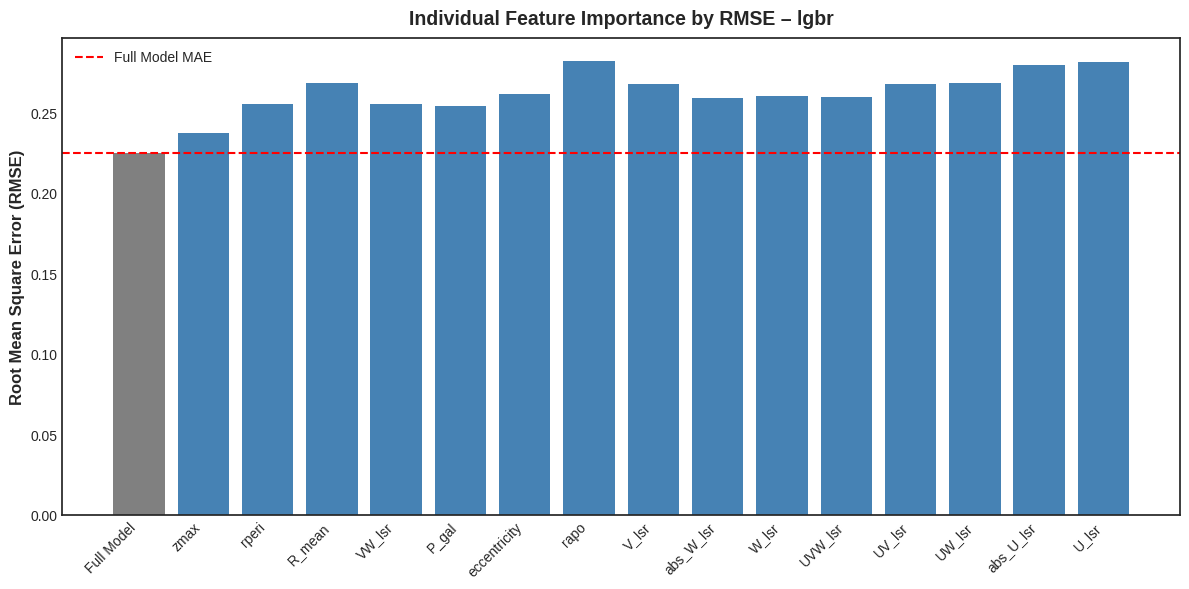

In [ ]:
from sklearn.base import clone

def individual_feature_importance(model, model_name, X, y, X_test, y_test):
    """
    Trains a model with each feature individually and compares MAE to full model.
    """
    model_full = clone(model)
    model_full.fit(X, y)

    feature_names = X.columns

    # Full prediction
    y_pred_full = model_full.predict(X_test)
    rmse_full =  np.sqrt(mean_squared_error(y_test, y_pred_full))

    # Individual feature performance
    rmse_individual = []
    for feature in feature_names:
        model_feat = clone(model)
        model_feat.fit(X[[feature]], y)
        y_pred_feat = model_feat.predict(X_test[[feature]])
        rmse_individual.append(np.sqrt(mean_squared_error(y_test, y_pred_feat))) 

    # Plot
    plt.figure(figsize=(12, 6))
    plt.bar(['Full Model'] + list(feature_names), [rmse_full] + rmse_individual, color=['gray'] + ['steelblue']*len(feature_names))
    plt.axhline(y=rmse_full, color='red', linestyle='--', label='Full Model MAE')

    plt.ylabel('Root Mean Square Error (RMSE)')
    plt.title(f'Individual Feature Importance by RMSE – {model_name}')
    plt.xticks(rotation=45, ha='right')
    plt.legend()
    plt.tight_layout()
    plt.show()
    return rmse_individual

lgbr = LGBMRegressor(random_state=random_state, verbosity=-1, n_jobs=-1)

model_names = {
    'lgbr': lgbr,
}
# Example for one model and one test set
best_model_name = 'lgbr'
model = model_names[best_model_name]
rmse_individual = individual_feature_importance(model, 'lgbr', X_combined_train[best_features], y_combined_train, X_harps[best_features], y_harps)

Feature importance: ['zmax' 'R_mean' 'eccentricity' 'rapo' 'rperi' 'UV_lsr' 'VW_lsr' 'U_lsr'
 'W_lsr' 'V_lsr' 'abs_W_lsr' 'UVW_lsr' 'P_gal' 'UW_lsr' 'abs_U_lsr']


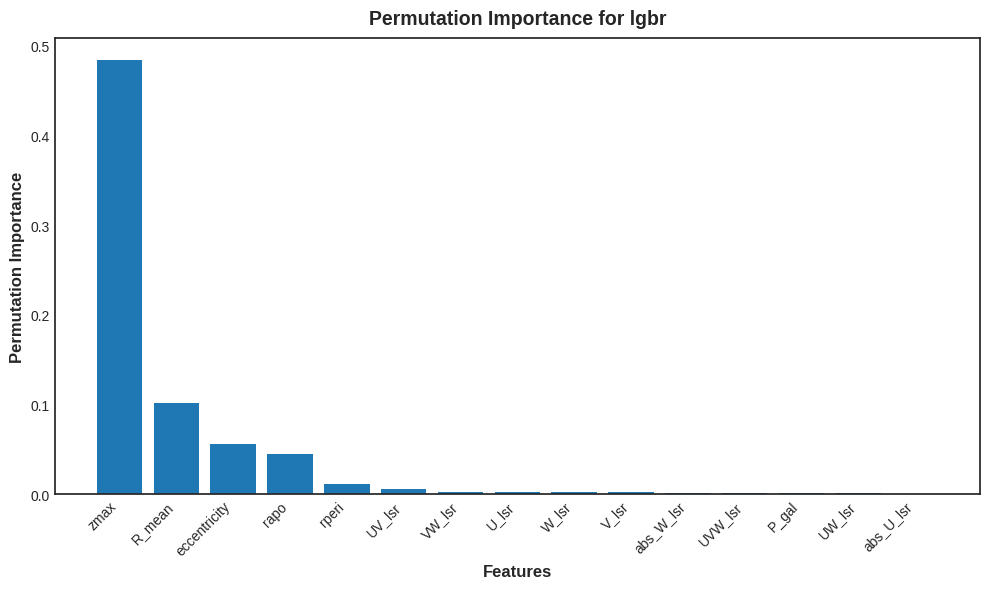

In [ ]:
def feat_importance_permut(model, model_name, X, y, n_repeats = 10):
    from sklearn.inspection import permutation_importance

    X_trian, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    model.fit(X_trian, y_train)
    

    # Calculate MAE on the original test set
    y_pred = model.predict(X_test)
    mae_original =  np.sqrt(mean_squared_error(y_test, y_pred))

    # Use permutation importance to obtain feature importances
    result = permutation_importance(model, X_test, y_test, n_repeats=n_repeats, random_state=42)

    # Get feature importances and indices
    feature_importances = result.importances_mean
    sorted_indices = feature_importances.argsort()[::-1]

    print (f'Feature importance: {X.columns[sorted_indices].values}')

    # Plot the feature importances
    plt.figure(figsize=(10, 6))
    plt.bar(range(len(sorted_indices)), feature_importances[sorted_indices], tick_label=X.columns[sorted_indices])
    plt.xlabel('Features')
    plt.ylabel('Permutation Importance')
    plt.title(f'Permutation Importance for {model_name}')
    plt.xticks(rotation=45, ha='right')
    plt.show()

feat_importance_permut(model, 'lgbr', X_combined_train[best_features], y_combined_train, n_repeats = 10)

In [ ]:
def ols(x, y):
    x_with_const = sm.add_constant(x)
    model = sm.OLS(y, x_with_const)
    results = model.fit()
    coeff1_ols, coeff2_ols = results.params[0], results.params[1]
    p_values = results.pvalues
    return coeff1_ols, coeff2_ols, p_values

MAE = 0.18


/tmp/ipykernel_16946/4033565634.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coeff1_ols, coeff2_ols = results.params[0], results.params[1]
/tmp/ipykernel_16946/4033565634.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coeff1_ols, coeff2_ols = results.params[0], results.params[1]
/tmp/ipykernel_16946/2257008830.py:35: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ax_i.set_title(f"{p_value[1]:.2f}")
/tmp/ipykernel_16946/40

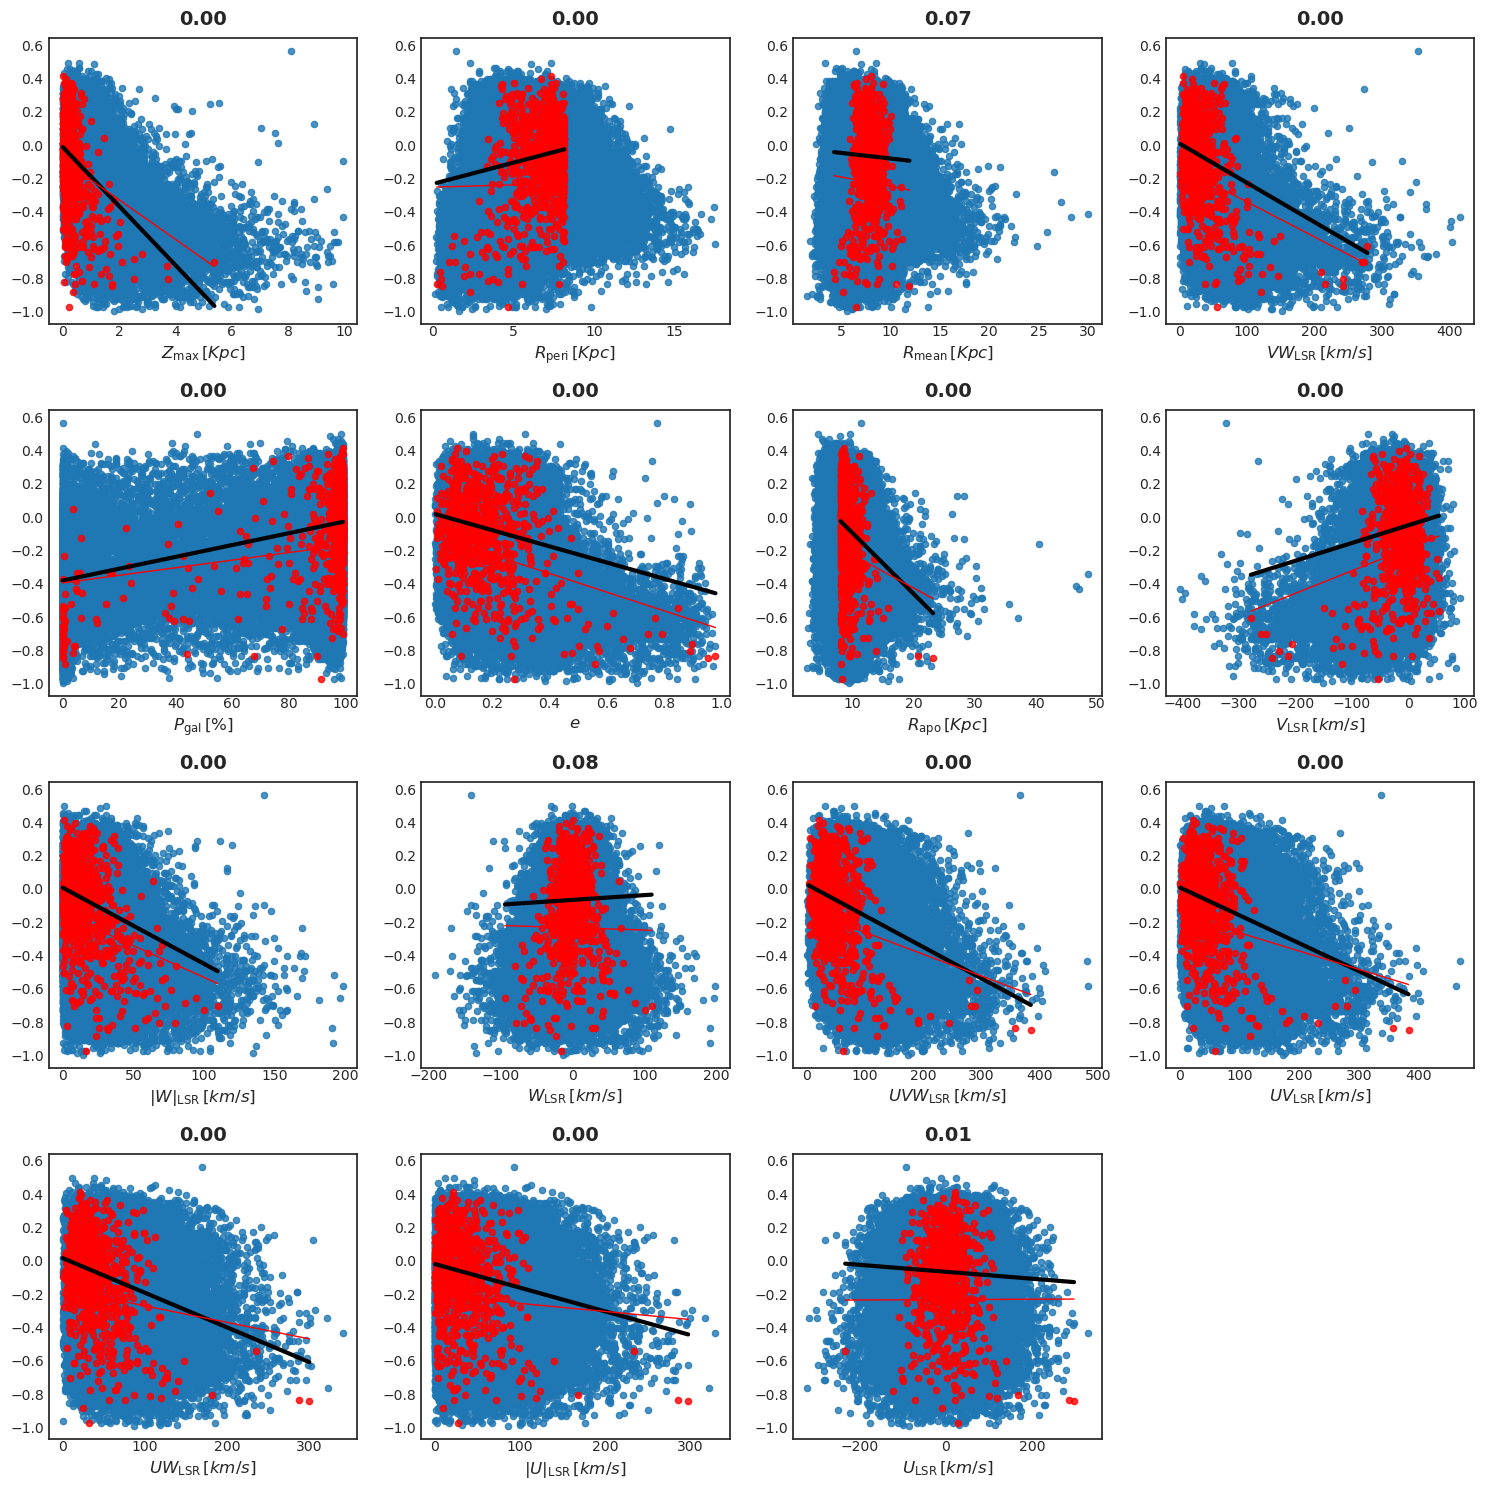

In [ ]:

def dependence_on_feature_plot(model, X, y, X_test, y_test):
    model.fit(X, y)
    y_pred = model.predict(X_test)
    print(f"MAE = {mean_absolute_error(y_test, y_pred):.2f}")

    # styling
    import seaborn as sns
    sns.set_style("white")
    fig, ax = plt.subplots(4, 4, figsize=(15, 15))
    axes = ax.flatten()

    # iterate features (cap at number of axes)
    for i, feature in enumerate(X.columns[:len(axes)]):
        # simple OLS on test and train
        coeff1_ols, coeff2_ols, p_value = ols(X_test[feature], y_pred)
        coeff1_tr, coeff2_tr, p_value_tr = ols(X[feature], y)

        # line range from test feature range
        x_min = np.nanmin(X_test[feature])
        x_max = np.nanmax(X_test[feature])
        x_line = np.linspace(x_min, x_max, 200)

        y_line = coeff1_ols + coeff2_ols * x_line
        y_line_tr = coeff1_tr + coeff2_tr * x_line

        ax_i = axes[i]
        ax_i.scatter(X[feature], y, s=20, alpha=0.8)
        ax_i.scatter(X_test[feature], y_test, s=20, color="red", alpha=0.8)
        ax_i.plot(x_line, y_line, lw=3, color="black")
        ax_i.plot(x_line, y_line_tr, lw=1, color="red", label="Train")

        # pretty xlabel
        ax_i.set_xlabel(PRETTY_LABELS.get(feature, feature), fontsize=12)
        # show p-value for test fit in title
        ax_i.set_title(f"{p_value[1]:.2f}")

        ax_i.tick_params(axis="x", which="major", labelsize=10, pad=0)
        ax_i.tick_params(axis="y", which="major", labelsize=10)

    # turn off any unused subplots
    for j in range(len(X.columns), len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

dependence_on_feature_plot(model, X_combined_train, y_combined_train, X_harps, y_harps)

/tmp/ipykernel_16946/4033565634.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coeff1_ols, coeff2_ols = results.params[0], results.params[1]
/tmp/ipykernel_16946/4004556215.py:53: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  p_slope = float(pvals[1])
/tmp/ipykernel_16946/4033565634.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coeff1_ols, coeff2_ols = results.params[0], results.params[1]
/tmp/ipykernel_16946/4004556215.p

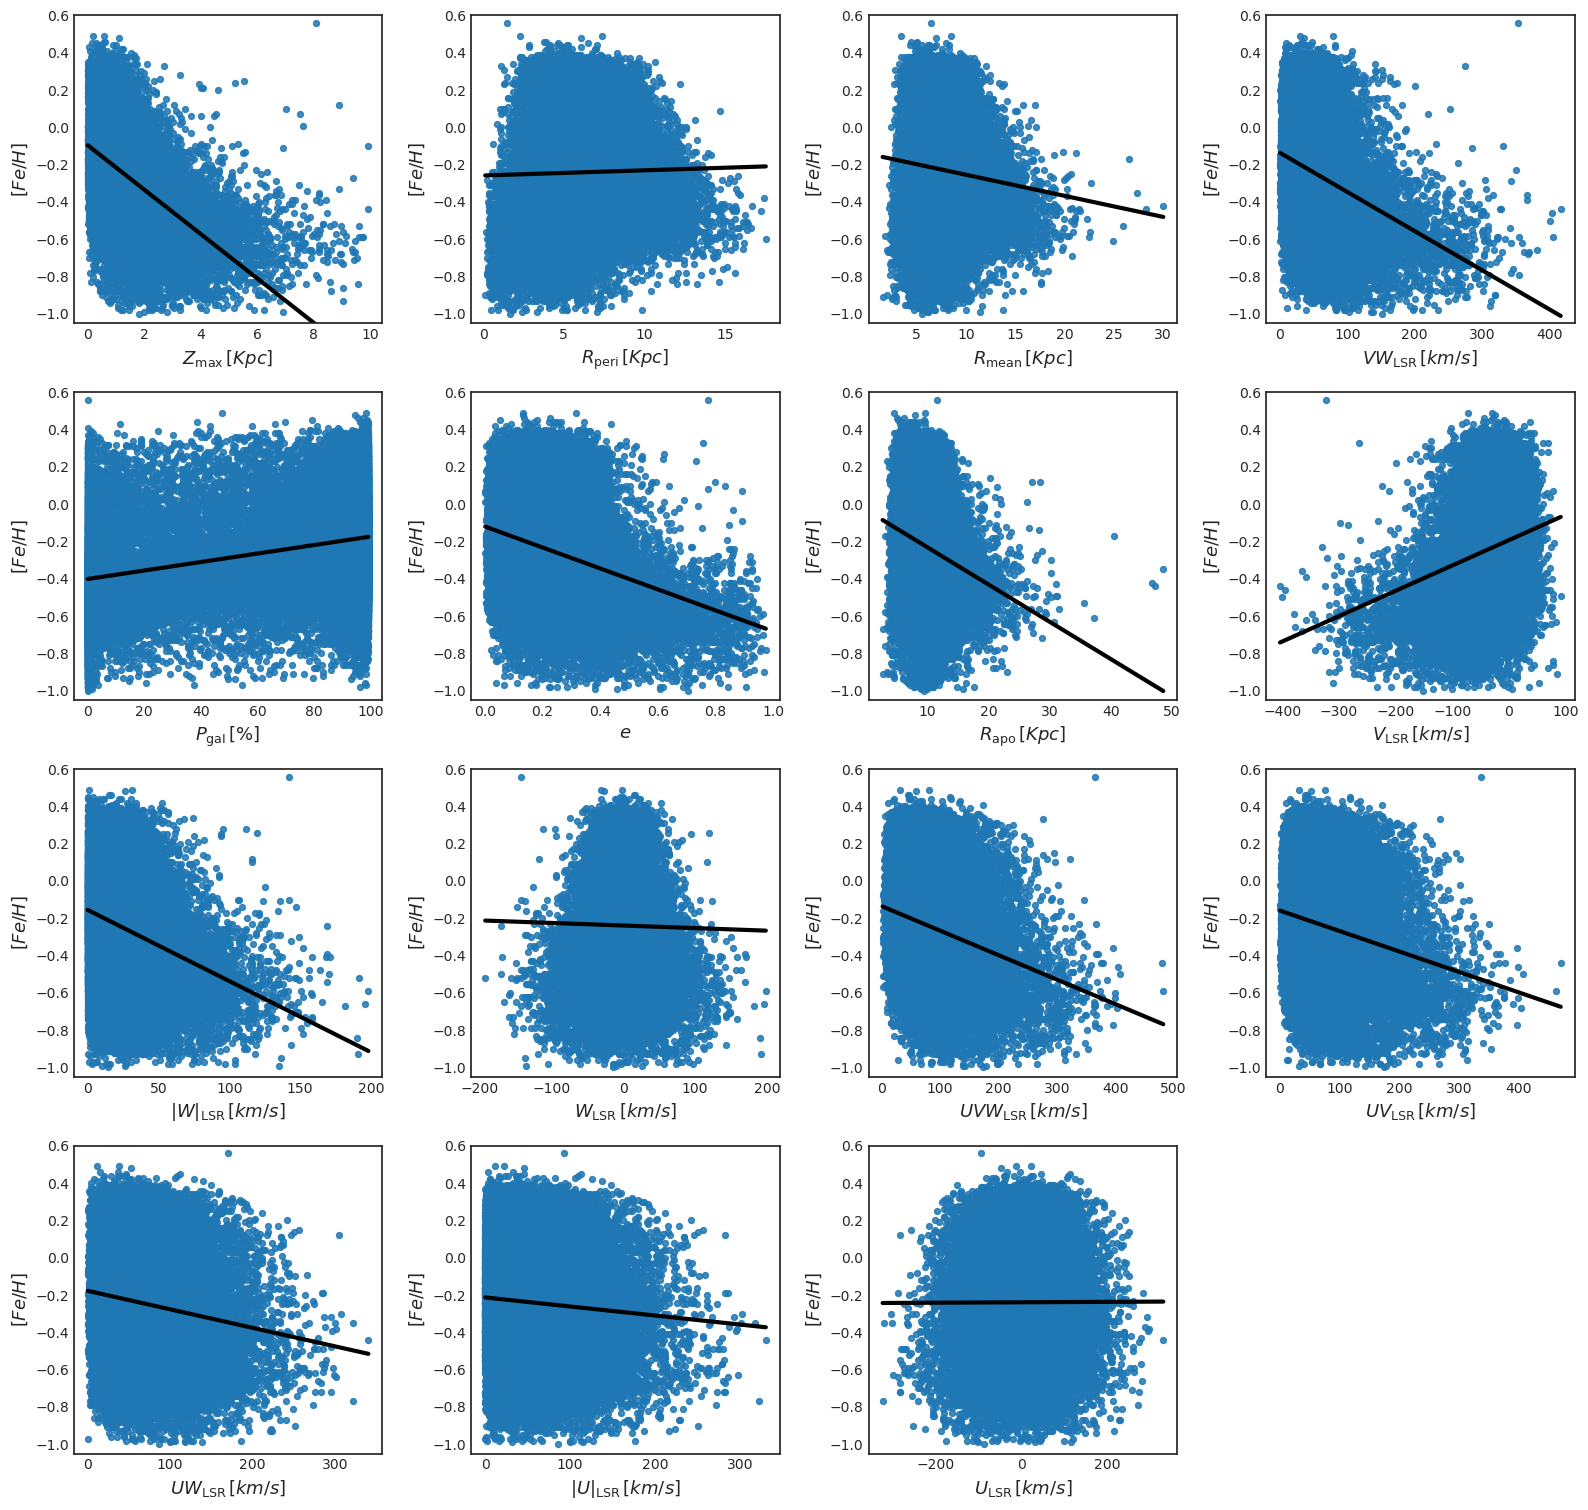

In [ ]:

def dependence_on_feature_plot_df(X, y, *, ncols=4, add_fit=True, ols_func=None):
    """
    Plot y as a function of each feature in X (single dataset).
    
    Parameters
    ----------
    X : pandas.DataFrame
        Features (columns will be iterated).
    y : array-like or pandas.Series
        Target values aligned with X.
    ncols : int, optional
        Number of columns in the subplot grid (default 4).
    add_fit : bool, optional
        If True, adds a best-fit line (OLS).
    ols_func : callable, optional
        Custom OLS function with signature (x, y) -> (intercept, slope, pvals_array_or_scalar).
        If None, uses np.polyfit for slope/intercept and omits p-values.
    """
    import numpy as np
    import matplotlib.pyplot as plt
    import seaborn as sns
    import math
    import pandas as pd

    # Ensure alignment & drop rows with NaNs in y or any feature being plotted
    data = pd.concat([X, pd.Series(y, index=X.index, name="_y")], axis=1)

    features = list(X.columns)
    n = len(features)
    nrows = math.ceil(n / ncols)

    sns.set_style("white")
    fig, ax = plt.subplots(nrows, ncols, figsize=(4*ncols, 3.8*nrows))
    axes = np.atleast_1d(ax).ravel()

    for i, feat in enumerate(features):
        ax_i = axes[i]
        df_i = data[[feat, "_y"]].dropna()

        x = df_i[feat].values
        yy = df_i["_y"].values

        # scatter
        ax_i.scatter(x, yy, s=18, alpha=0.85)

        title_txt = ""
        if add_fit and len(df_i) >= 2:
            # Fit line using provided OLS or fallback to np.polyfit
            if ols_func is not None:
                c0, c1, pvals = ols_func(df_i[feat], df_i["_y"])
                # p-value: if array-like, assume slope at index 1
                try:
                    p_slope = float(pvals[1])
                except Exception:
                    p_slope = float(pvals)
                title_txt = f"$p_{{\\mathrm{{slope}}}}$ = {p_slope:.2e}"
            else:
                # Fallback: least squares (no p-value)
                c1, c0 = np.polyfit(x, yy, 1)
                title_txt = r"OLS fit (no $p$)"

            # line
            x_line = np.linspace(np.nanmin(x), np.nanmax(x), 200)
            y_line = c0 + c1 * x_line
            ax_i.plot(x_line, y_line, lw=3, color="black")

        ax_i.set_xlabel(PRETTY_LABELS.get(feat, feat), fontsize=13)
        ax_i.set_ylim(-1.05, 0.6)
        ax_i.set_ylabel(r"$[Fe/H]$", fontsize=13)
        #if title_txt:
        #    ax_i.set_title(title_txt, fontsize=11)
        ax_i.tick_params(axis="both", labelsize=10)

    # remove unused axes
    for j in range(n, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.savefig('dependence_on_feature_plot_df.png', dpi=300)
    plt.show()



# If you have your existing `ols` function:
dependence_on_feature_plot_df(X_apogee, y_apogee, ncols=4, add_fit=True, ols_func=ols)

# Or without p-values (fallback fit):
# dependence_on_feature_plot_df(X_one, y_one, ncols=4, add_fit=True)


In [ ]:
def evaluate_on_test_data(X_train, y_train, test_df, target, models, test_name='Test'):
    """
    Trains models on the full training set and evaluates on a test set.

    Parameters:
        X_train, y_train: Training features and target.
        test_df: DataFrame containing the test data (including the target column).
        target (str): Name of the target column in test_df.
        models: Dictionary of model_name: model_instance.
        test_name (str): Label for this test set (e.g., 'Apogee', 'HARPS').

    Returns:
        dict: model_name → test MAE and baseline MAE
    """
    X_test = test_df.drop(columns=[target])
    y_test = test_df[target]

    results = {}

    for name, model in models.items():
        print(f"Training and evaluating {name} on {test_name}")
        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)

        mae_model = mean_absolute_error(y_test, y_pred)
        rmse_model = np.sqrt(mean_squared_error(y_test, y_pred))
        mae_baseline = mean_absolute_error(y_test, [y_test.mean()] * len(y_test))
        rmse_baseline = np.sqrt(mean_squared_error(y_test, [y_test.mean()] * len(y_test)))


        results[name] = {
            'rmse_model': rmse_model,
            'rmse_baseline': rmse_baseline
        }

        print(f"{name} | {test_name} RMSE: {rmse_model:.3f} (mean baseline: {rmse_baseline:.3f})\n")

    return results


In [ ]:
# Evaluate on Apogee test
results_apogee = evaluate_on_test_data(
    X_combined_train, y_combined_train,
    test_df=apogee_test,
    target='fe_h',
    models=model_names,
    test_name='Apogee'
)

# Evaluate on HARPS test
results_harps = evaluate_on_test_data(
    X_combined_train, y_combined_train,
    test_df=harps,
    target='fe_h',
    models=model_names,
    test_name='HARPS'
)

# Evaluate on GALAH test
results_galah = evaluate_on_test_data(
    X_combined_train, y_combined_train,
    test_df=galah,
    target='fe_h',
    models=model_names,
    test_name='GALAH'
)

Training and evaluating lgbr on Apogee
lgbr | Apogee RMSE: 0.198 (mean baseline: 0.262)

Training and evaluating lgbr on HARPS
lgbr | HARPS RMSE: 0.225 (mean baseline: 0.259)

Training and evaluating lgbr on GALAH
lgbr | GALAH RMSE: 0.200 (mean baseline: 0.216)



In [ ]:
def plot_residuals_vs_features(X, y_true, y_pred, feature_names=None, model_name='Model', sample_name='Test Set'):
    """
    Plot residuals (y_true - y_pred) vs each feature in X.

    Parameters:
        X: DataFrame or array of features.
        y_true: True target values.
        y_pred: Predicted target values.
        feature_names: Optional list of feature names.
        model_name: For labeling plots.
        sample_name: Dataset name for titles.
    """
    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd

    if isinstance(X, np.ndarray):
        X = pd.DataFrame(X, columns=feature_names if feature_names else [f'feature_{i}' for i in range(X.shape[1])])

    residuals = np.array(y_true) - np.array(y_pred)

    num_features = X.shape[1]
    ncols = 3
    nrows = int(np.ceil(num_features / ncols))

    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(5 * ncols, 4 * nrows))

    for idx, col in enumerate(X.columns):
        ax = axes.flatten()[idx]
        ax.scatter(X[col], residuals, alpha=0.6, s=20)
        ax.axhline(0, color='gray', linestyle='--')
        ax.set_xlabel(col)
        ax.set_ylabel('Residual')
        ax.set_title(f'{col} vs Residual')

    for j in range(idx + 1, nrows * ncols):
        fig.delaxes(axes.flatten()[j])  # Remove empty subplots

    fig.suptitle(f'{model_name} Residuals vs Features ({sample_name})', fontsize=16)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def plot_residuals_vs_true(y_true, y_pred, model_name='Model', sample_name='Test Set'):
    """
    Plot residuals (y_true - y_pred) vs y_true, and residuals from predicting the mean.

    Parameters:
        y_true: Ground truth target values.
        y_pred: Model predictions.
        model_name: Name of the model for labeling.
        sample_name: Name of the dataset (e.g., 'Apogee' or 'HARPS').
    """
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_mean = np.full_like(y_true, y_true.mean())

    residuals_model = y_true - y_pred
    residuals_mean = y_true - y_mean

    plt.figure(figsize=(10, 6))
    plt.scatter(y_true, residuals_model, alpha=0.6, label=f'{model_name}', s=20)
    plt.scatter(y_true, residuals_mean, alpha=0.4, label='Mean predictor', s=20, marker='x')

    plt.axhline(0, color='gray', linestyle='--')
    plt.xlabel('True Value (y)')
    plt.ylabel('Residual (y_true - y_pred)')
    plt.title(f'Residuals vs True Values ({sample_name})')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


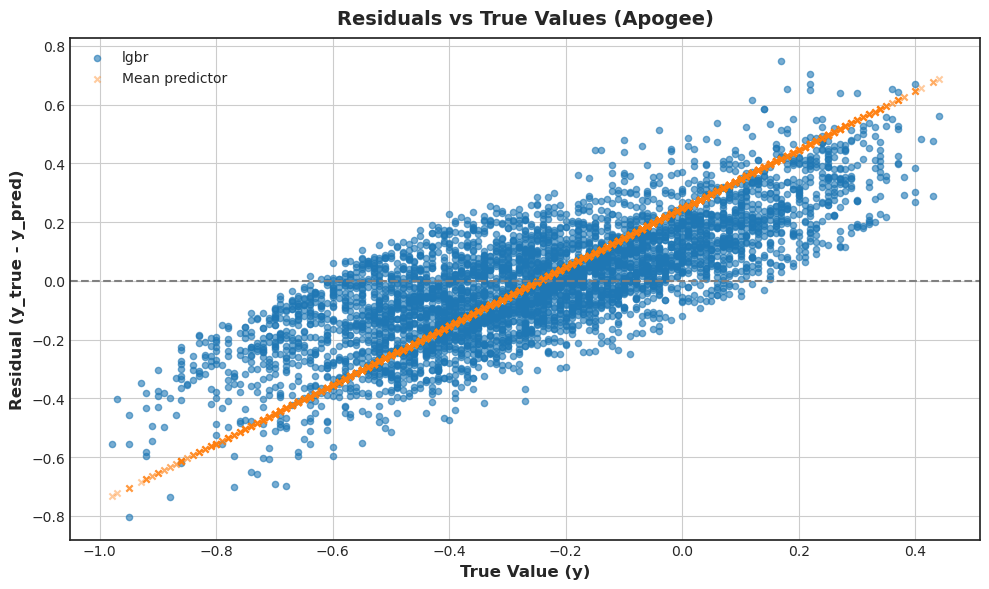

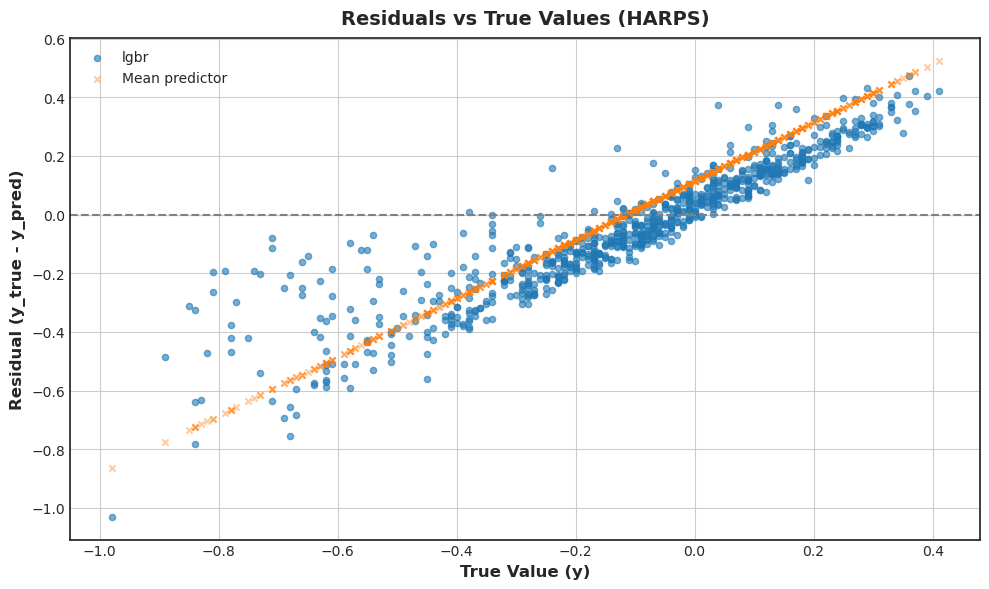

In [ ]:
# Example for one model and one test set
best_model_name = 'lgbr'
model = model_names[best_model_name]
model.fit(X_combined_train, y_combined_train)

y_pred_apogee = model.predict(X_apogee_test)
plot_residuals_vs_true(y_apogee_test, y_pred_apogee, model_name=best_model_name, sample_name='Apogee')

y_pred_harps = model.predict(X_harps)
plot_residuals_vs_true(y_harps, y_pred_harps, model_name=best_model_name, sample_name='HARPS')

#y_pred_galah = model.predict(X_galah_test)
#plot_residuals_vs_true(y_galah_test, y_pred_galah, model_name=best_model_name, sample_name='GALAH')


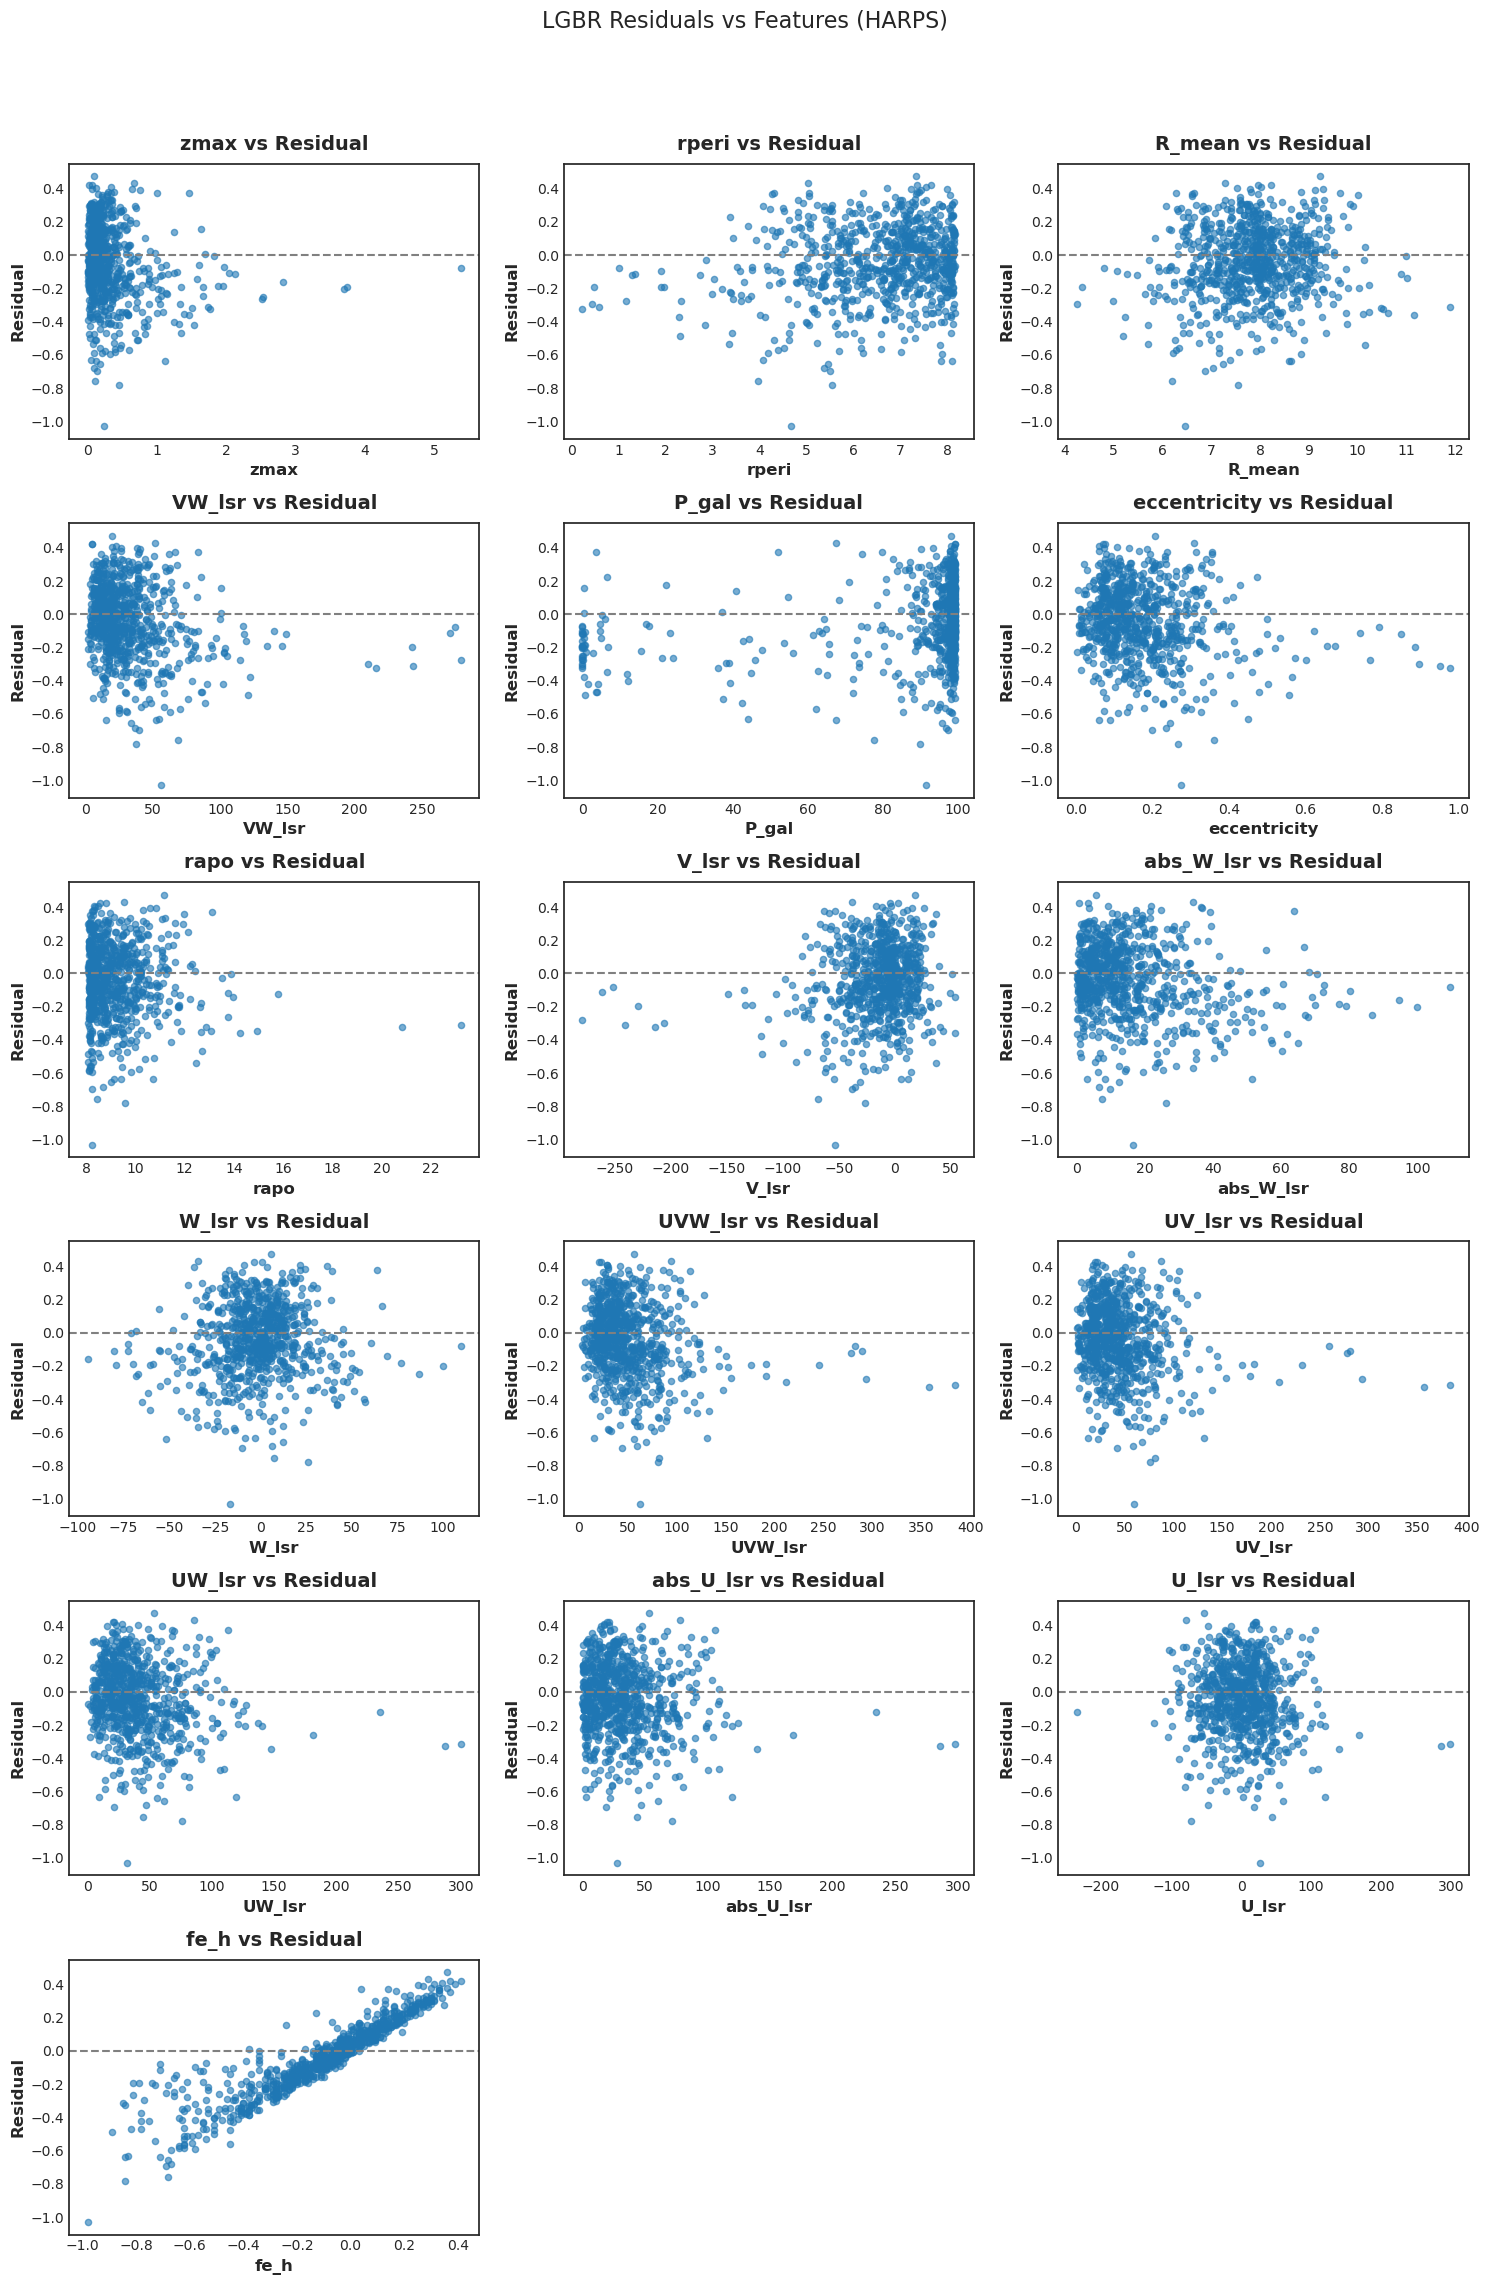

In [ ]:
plot_residuals_vs_features(harps, y_harps, y_pred_harps, model_name='LGBR', sample_name='HARPS')

In [ ]:
from copy import deepcopy
import random

class FeatureRemovingAdding:
    def __init__(self, verbose=True, tolerance=1e-5):
        self.verbose = verbose
        self.tolerance = tolerance
        self.history = []

    def _log(self, msg):
        if self.verbose:
            print(msg)

    def feature_to_remove(self, all_features, X, y, model_test_cv, maximize=True):
        best_score = model_test_cv(X[all_features], y)
        self._log(f'All features: {len(all_features)}')
        self._log(f'List of input features: {all_features}')
        self._log(f'With all features: score = {best_score:.5f}')

        best_feature_to_remove = None

        for i, feature in enumerate(all_features):
            test_feature = all_features.copy()
            test_feature.remove(feature)

            new_score = model_test_cv(X[test_feature], y)
            self._log(f'{i+1}/{len(all_features)}: Removing {feature} -> score = {new_score:.5f}')

            if ((maximize and new_score > best_score + self.tolerance) or
                (not maximize and new_score < best_score - self.tolerance)):
                self._log(f'New best score: {new_score:.5f} (was {best_score:.5f})')
                best_score = new_score
                best_feature_to_remove = feature

        return best_feature_to_remove

    def iterative_feature_removal(self, all_features, X, y, model_test_cv, min_features=2, maximize=True):
        all_features = all_features.copy()
        removed_features = []

        while len(all_features) > min_features:
            best_feature_to_remove = self.feature_to_remove(all_features.copy(), X, y, model_test_cv, maximize)
            if best_feature_to_remove is None:
                break

            removed_features.append(best_feature_to_remove)
            all_features.remove(best_feature_to_remove)
            self._log(f"Removing feature: {best_feature_to_remove}")
            self.history.append((len(all_features), model_test_cv(X[all_features], y)))

        self._log(f"Optimal set of features: {all_features}")
        self._log(f"All removed features: {removed_features}")
        return all_features

    def feature_to_add(self, all_features, removed_features, X, y, model_test_cv, maximize=True):
        best_score = model_test_cv(X[all_features], y)
        self._log(f'Current features: {len(all_features)}')
        self._log(f'With current features: score = {best_score:.5f}')

        best_feature_to_add = None

        for i, feature in enumerate(removed_features):
            test_feature = all_features.copy()
            test_feature.append(feature)

            new_score = model_test_cv(X[test_feature], y)
            self._log(f'{i+1}/{len(removed_features)}: Adding {feature} -> score = {new_score:.5f}')

            if ((maximize and new_score > best_score + self.tolerance) or
                (not maximize and new_score < best_score - self.tolerance)):
                self._log(f'New best score: {new_score:.5f} (was {best_score:.5f})')
                best_score = new_score
                best_feature_to_add = feature

        return best_feature_to_add

    def iterative_feature_adding(self, all_features, removed_features, X, y, model_test_cv, maximize=True):
        all_features = all_features.copy()
        removed_features = removed_features.copy()
        total_features = len(all_features) + len(removed_features)

        while len(all_features) < total_features:
            best_feature_to_add = self.feature_to_add(all_features.copy(), removed_features.copy(), X, y, model_test_cv, maximize)
            if best_feature_to_add is None:
                break

            all_features.append(best_feature_to_add)
            removed_features.remove(best_feature_to_add)
            self._log(f"Adding feature: {best_feature_to_add}")
            self.history.append((len(all_features), model_test_cv(X[all_features], y)))

        self._log(f"Optimal set of features: {all_features}")
        self._log(f"All remaining removed features: {removed_features}")
        return all_features
    
    

    def forward_backward_selection(self, X, y, model_test_cv, 
                                initial_features=None, 
                                all_features=None, 
                                maximize=True):
        if all_features is None:
            all_features = list(X.columns)

        if initial_features is None:
            initial_features = [random.choice(all_features)]
            self._log(f"Randomly selected initial feature: {initial_features[0]}")

        current_features = initial_features.copy()
        remaining_features = [f for f in all_features if f not in current_features]
        current_score = model_test_cv(X[current_features], y)
        self.history.append((len(current_features), current_score))
        self._log(f"Initial score with {current_features}: {current_score:.5f}")

        improved = True
        while improved:
            improved = False

            # === Try adding ===
            best_add, best_add_score = None, current_score
            for f in remaining_features:
                trial_features = current_features + [f]
                score = model_test_cv(X[trial_features], y)
                self._log(f"Trying to add {f}: score = {score:.5f}")

                if (maximize and score > best_add_score + self.tolerance) or \
                (not maximize and score < best_add_score - self.tolerance):
                    best_add, best_add_score = f, score

            if best_add:
                current_features.append(best_add)
                remaining_features.remove(best_add)
                current_score = best_add_score
                self.history.append((len(current_features), current_score))
                self._log(f"Added {best_add}, new score = {current_score:.5f}")
                improved = True

            # === Try removing ===
            best_remove, best_remove_score = None, current_score
            for f in current_features:
                trial_features = [x for x in current_features if x != f]
                score = model_test_cv(X[trial_features], y)
                self._log(f"Trying to remove {f}: score = {score:.5f}")

                if (maximize and score > best_remove_score + self.tolerance) or \
                (not maximize and score < best_remove_score - self.tolerance):
                    best_remove, best_remove_score = f, score

            if best_remove:
                current_features.remove(best_remove)
                remaining_features.append(best_remove)
                current_score = best_remove_score
                self.history.append((len(current_features), current_score))
                self._log(f"Removed {best_remove}, new score = {current_score:.5f}")
                improved = True

        self._log(f"Final feature set: {current_features} with score = {current_score:.5f}")
        return {
            'start': initial_features,
            'final_features': current_features,
            'final_score': current_score
        }

    
    def multi_start_forward_backward_selection(self, X, y, model_test_cv, 
                                        all_features=None, 
                                        maximize=True, 
                                        n_starts=10, 
                                        random_state=random_state):
        if all_features is None:
            all_features = list(X.columns)

        best_score = None
        best_result = None
        all_results = []

        rng = random.Random(random_state)

        for i in range(n_starts):
            start_feature = [rng.choice(all_features)]
            self._log(f"\n=== Run {i+1}/{n_starts} starting with: {start_feature[0]} ===")

            result = self.forward_backward_selection(
                X=X,
                y=y,
                model_test_cv=model_test_cv,
                initial_features=start_feature,
                all_features=all_features,
                maximize=maximize
            )

            all_results.append(result)

            if (maximize and (best_score is None or result['final_score'] > best_score)) or \
            (not maximize and (best_score is None or result['final_score'] < best_score)):
                best_score = result['final_score']
                best_result = result

        self._log(f"\n=== Summary of {n_starts} runs ===")
        for i, res in enumerate(all_results):
            self._log(f"{i+1}: Started with {res['start'][0]}, Final score = {res['final_score']:.5f}, Features: {res['final_features']}")

        self._log(f"\n>>> Best result: score = {best_result['final_score']:.5f}")
        self._log(f">>> Best feature set: {best_result['final_features']}")
        
        return best_result
    
    def random_search_with_greedy_refinement(self, X, y, model_test_cv, 
                                         all_features=None,
                                         maximize=False,
                                         n_random=20,
                                         top_k=3,
                                         subset_size_range=(2, 5),
                                         random_state=42):
        """
        Step 1: Try N random feature subsets and keep the top K by score.
        Step 2: Refine each of the top K using forward-backward selection.
        """

        if all_features is None:
            all_features = list(X.columns)

        rng = random.Random(random_state)
        evaluated_subsets = []

        print(f"\n--- RANDOM SEARCH PHASE ({n_random} trials) ---")
        for i in range(n_random):
            k = rng.randint(*subset_size_range)
            subset = rng.sample(all_features, k)
            score = model_test_cv(X[subset], y)
            evaluated_subsets.append({'subset': subset, 'score': score})
            print(f"{i+1}/{n_random}: Score = {score:.5f}, Features = {subset}")

        # Sort: best score first
        sorted_subsets = sorted(
            evaluated_subsets,
            key=lambda d: d['score'],
            reverse=maximize
        )

        print(f"\n--- TOP {top_k} SUBSETS TO REFINE ---")
        top_candidates = sorted_subsets[:top_k]
        for i, entry in enumerate(top_candidates):
            print(f"{i+1}: Score = {entry['score']:.5f}, Features = {entry['subset']}")

        print("\n--- GREEDY REFINEMENT PHASE ---")
        best_result = None
        best_score = None
        for i, entry in enumerate(top_candidates):
            print(f"\nRefining candidate {i+1}/{top_k}...")
            result = self.forward_backward_selection(
                X=X,
                y=y,
                model_test_cv=model_test_cv,
                initial_features=entry['subset'],
                all_features=all_features,
                maximize=maximize
            )
            score = result['final_score']
            print(f"Refined Score = {score:.5f}, Final Features = {result['final_features']}")

            if (maximize and (best_score is None or score > best_score)) or \
            (not maximize and (best_score is None or score < best_score)):
                best_score = score
                best_result = result

        print(f"\n>>> BEST FINAL RESULT: Score = {best_result['final_score']:.5f}")
        print(f">>> Feature Set = {best_result['final_features']}")

        return best_result






In [ ]:
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error
import numpy as np

from sklearn.base import clone


def model_test_cv(X, y, model, k=5, random_state=42, scorer='mae'):
    kf = KFold(n_splits=k, shuffle=True, random_state=random_state)
    scores = []

    for train_index, test_index in kf.split(X):
        X_train, X_test = X.iloc[train_index], X.iloc[test_index]
        y_train, y_test = y.iloc[train_index], y.iloc[test_index]

        # Create a fresh clone of the model for each fold
        model_instance = clone(model)
        model_instance.fit(X_train, y_train)
        y_pred = model_instance.predict(X_test)

        if scorer == 'mae':
            scores.append(mean_absolute_error(y_test, y_pred))
        else:
            raise ValueError("Unsupported scorer: use 'mae'")

    return np.mean(scores)


In [ ]:
def wrapped_cv(X, y):
    return model_test_cv(X, y, model=model, k=5, scorer='mae')

In [ ]:
X_combined_train.columns

Index(['zmax', 'jz', 'P_gal', 'Log_UVW_lsr', 'VW_lsr', 'UVW_lsr', 'jp', 'Tz',
       'Oz', 'jr', 'eccentricity', 'V_lsr', 'abs_W_lsr', 'rperi', 'Or',
       'UW_lsr', 'rapo'],
      dtype='object')

In [ ]:
all_features = ['zmax',
 'jz',
 'P_gal',
 'Log_UVW_lsr',
 'VW_lsr',
 'UVW_lsr',
 'jp',
 'Tz',
 'Oz',
 'jr',
 'eccentricity',
 'V_lsr',
 'abs_W_lsr',
 'rperi',
 'Or',
 'UW_lsr',
 'rapo']



#>>> BEST FINAL RESULT: Score = 0.15031
#>>> Feature Set = ['Oz', 'jp', 'rapo', 'zmax', 'Or', 'UVW_lsr', 'V_lsr', 'P_gal', 'jz', 'VW_lsr', 'Log_UVW_lsr']

In [ ]:
fra = FeatureRemovingAdding(verbose=True)

best_features_result = fra.random_search_with_greedy_refinement(
    X=X_combined_train,
    y=y_combined_train,
    model_test_cv=wrapped_cv,
    all_features=all_features,
    maximize=False,
    n_random=200,
    top_k=5,
    subset_size_range=(2, 10),
    random_state=random_state
)



--- RANDOM SEARCH PHASE (200 trials) ---
1/200: Score = 0.15227, Features = ['zmax', 'Oz', 'Log_UVW_lsr']
2/200: Score = 0.15281, Features = ['VW_lsr', 'Log_UVW_lsr', 'eccentricity', 'V_lsr', 'Oz']
3/200: Score = 0.15266, Features = ['rperi', 'jz', 'zmax']
4/200: Score = 0.15191, Features = ['jp', 'Tz', 'Oz']
5/200: Score = 0.16441, Features = ['jp', 'rperi']
6/200: Score = 0.15077, Features = ['Or', 'Oz', 'abs_W_lsr', 'rperi', 'zmax']
7/200: Score = 0.15650, Features = ['rperi', 'eccentricity', 'VW_lsr', 'P_gal']
8/200: Score = 0.15073, Features = ['eccentricity', 'Log_UVW_lsr', 'jz', 'jp', 'Or']
9/200: Score = 0.15092, Features = ['V_lsr', 'Oz', 'abs_W_lsr', 'zmax', 'rapo', 'Tz', 'UW_lsr']
10/200: Score = 0.15425, Features = ['abs_W_lsr', 'P_gal', 'Oz']
11/200: Score = 0.15048, Features = ['V_lsr', 'jp', 'rapo', 'jz', 'zmax', 'eccentricity']
12/200: Score = 0.15108, Features = ['jr', 'P_gal', 'rperi', 'Log_UVW_lsr', 'jz']
13/200: Score = 0.15096, Features = ['Oz', 'Or', 'eccentricit

In [ ]:
fra = FeatureRemovingAdding(verbose=True)

#best_features = fra.multi_start_forward_backward_selection(
#    X=X_combined_train,
#    y=y_combined_train,
#    model_test_cv=wrapped_cv,
#    all_features=all_features,
#    maximize=False,
#    n_starts=10
#)


In [ ]:
from tpot import TPOTRegressor
from sklearn.model_selection import train_test_split

# Split data
X_train, X_test, y_train, y_test =     X_combined_train, X_harps, y_combined_train, y_harps

# Instantiate TPOT
tpot = TPOTRegressor(
    generations=5,             # number of evolutionary cycles
    population_size=20,         # number of models per generation
    verbosity=2,                # verbosity: 0 = silent, 3 = very detailed
    scoring='neg_mean_absolute_error',  # use MAE as metric
    random_state=random_state,
    n_jobs=-1                   # use all CPUs
)

# Fit TPOT
tpot.fit(X_train, y_train)

# Score on test set
print("Test MAE:", -tpot.score(X_test, y_test))  # negate because TPOT uses neg_MAE

# Export the best pipeline as Python code
tpot.export('best_pipeline.py')



/home/vadibekyan/anaconda3/lib/python3.12/site-packages/stopit/__init__.py:10: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor


/home/vadibekyan/anaconda3/lib/python3.12/site-packages/sklearn/base.py:1206: FutureWarning: passing a class to None is deprecated and will be removed in 1.8. Use an instance of the class instead.
  warnings.warn(
/home/vadibekyan/anaconda3/lib/python3.12/site-packages/sklearn/base.py:1246: FutureWarning: passing a class to None is deprecated and will be removed in 1.8. Use an instance of the class instead.
  warnings.warn(


is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor


Version 0.12.2 of tpot is outdated. Version 1.1.0 was released Thursday July 03, 2025.


Optimization Progress:   0%|          | 0/120 [00:00<?, ?pipeline/s]

... (6 outputs left out)

/home/vadibekyan/anaconda3/lib/python3.12/site-packages/stopit/__init__.py:10: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/home/vadibekyan/anaconda3/lib/python3.12/site-packages/stopit/__init__.py:10: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/home/vadibekyan/anaconda3/lib/python3.12/site-packages/stopit/__init__.py:10: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setupt


Generation 4 - Current best internal CV score: -0.15023343594471752


/home/vadibekyan/anaconda3/lib/python3.12/site-packages/stopit/__init__.py:10: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/home/vadibekyan/anaconda3/lib/python3.12/site-packages/stopit/__init__.py:10: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/home/vadibekyan/anaconda3/lib/python3.12/site-packages/stopit/__init__.py:10: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setupt


Generation 5 - Current best internal CV score: -0.15017453353098653

Best pipeline: RandomForestRegressor(input_matrix, bootstrap=True, max_features=0.3, min_samples_leaf=20, min_samples_split=13, n_estimators=100)
Test MAE: 0.173011113804636
